# H1 · Weekend sales versus weekday sales

**Purpose.** Test the team hypothesis: *all product groups sell more on weekends (Saturday and Sunday) than on weekdays (Monday to Friday).*

We use the prepared dataset from the data-preparation step. The primary analysis uses the training period only, keeping the validation year available for later modelling. We compare average daily revenue for each product group and use a one-sided Welch t-test because the hypothesis has a direction and the two groups may have different variances.

**Interpretation rule, written before seeing the results.** H1 is supported only if every product group has a higher weekend mean and a one-sided p-value below 0.05. A significant result shows an association in these data; it does not prove that the weekend itself causes the difference.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind

ROOT = Path.cwd().parent if Path.cwd().name == "1_DatasetCharacteristics" else Path.cwd()
DATA_FILE = ROOT / "0_DataPreparation" / "output" / "bakery_prepared.csv"

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}
GROUP_ORDER = list(GROUPS.values())
ALPHA = 0.05

assert DATA_FILE.exists(), f"Prepared data not found: {DATA_FILE}"
data = pd.read_csv(DATA_FILE, parse_dates=["Datum"])
data["group"] = data["Warengruppe"].map(GROUPS)
data["weekday"] = pd.Categorical(data["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)
data["period"] = data["weekday"].isin(["Saturday", "Sunday"]).map({True: "Weekend", False: "Weekday"})

assert data["group"].notna().all(), "Every product group must have a known label"
assert data["Umsatz"].gt(0).all(), "Revenue must be positive"
assert data["split"].isin(["train", "validation"]).all(), "Unexpected split label"

analysis = data.loc[data["split"] == "train"].copy()
assert analysis["Datum"].max() < pd.Timestamp("2017-08-01"), "Primary analysis must use training dates only"
assert analysis["period"].notna().all(), "Every row must be classified as weekday or weekend"
print(f"Loaded {len(data):,} prepared rows; analysing {len(analysis):,} training rows.")
print(f"Analysis period: {analysis['Datum'].min().date()} to {analysis['Datum'].max().date()}")

Loaded 9,264 prepared rows; analysing 7,487 training rows.
Analysis period: 2013-07-01 to 2017-07-31


## 1. Check the comparison groups

The source contains one row for each date and product group when that group was recorded as sold. We do not add zero-revenue rows for closed or not-offered days. The check below confirms the weekday order and shows how many observations enter each comparison.

In [2]:
counts = (
    analysis.pivot_table(index="group", columns="period", values="Umsatz", aggfunc="size", observed=False)
    .reindex(GROUP_ORDER)
    .reindex(columns=["Weekday", "Weekend"])
)
assert counts.notna().all().all(), "Every group needs both weekday and weekend observations"
counts.astype(int)

period,Weekday,Weekend
group,,
Bread,1045,416
Rolls,1045,416
Croissants,1045,416
Confectionery,1002,406
Cakes,1045,416
Seasonal bread,169,66


## 2. Descriptive comparison

First compare the means without using a significance test. The percentage difference is calculated as `(weekend mean - weekday mean) / weekday mean`.

In [3]:
means = (
    analysis.pivot_table(index="group", columns="period", values="Umsatz", aggfunc="mean", observed=False)
    .reindex(GROUP_ORDER)
    .reindex(columns=["Weekday", "Weekend"])
)
descriptive = means.rename(columns={"Weekday": "weekday_mean", "Weekend": "weekend_mean"})
descriptive["difference"] = descriptive["weekend_mean"] - descriptive["weekday_mean"]
descriptive["percent_difference"] = 100 * descriptive["difference"] / descriptive["weekday_mean"]
descriptive.round(1)

period,weekday_mean,weekend_mean,difference,percent_difference
group,,,,
Bread,126.0,109.7,-16.3,-13.0
Rolls,367.6,518.5,150.9,41.1
Croissants,147.9,204.9,57.0,38.6
Confectionery,78.5,112.4,33.9,43.1
Cakes,267.5,314.5,47.0,17.6
Seasonal bread,66.7,67.4,0.6,0.9


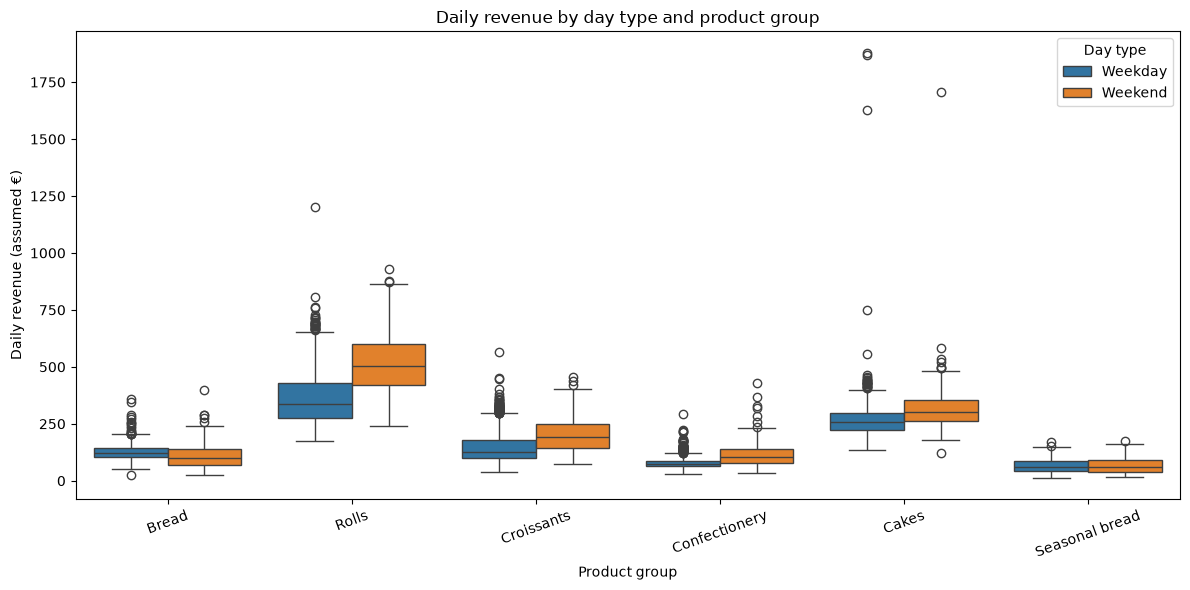

In [4]:
plot_data = analysis.copy()
plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, x="group", y="Umsatz", hue="period", order=GROUP_ORDER, hue_order=["Weekday", "Weekend"])
plt.title("Daily revenue by day type and product group")
plt.xlabel("Product group")
plt.ylabel("Daily revenue (assumed €)")
plt.xticks(rotation=20)
plt.legend(title="Day type")
plt.tight_layout()
plt.show()

## 3. Welch t-tests

For each product group, the null hypothesis is that weekend revenue is not greater than weekday revenue. The alternative is that weekend revenue is greater. Welch's test does not require equal variances.

In [5]:
test_rows = []
for group in GROUP_ORDER:
    weekday = analysis.loc[(analysis["group"] == group) & (analysis["period"] == "Weekday"), "Umsatz"]
    weekend = analysis.loc[(analysis["group"] == group) & (analysis["period"] == "Weekend"), "Umsatz"]
    test = ttest_ind(weekend, weekday, equal_var=False, alternative="greater")
    test_rows.append({
        "group": group,
        "weekday_n": len(weekday),
        "weekend_n": len(weekend),
        "weekday_mean": weekday.mean(),
        "weekend_mean": weekend.mean(),
        "difference": weekend.mean() - weekday.mean(),
        "percent_difference": 100 * (weekend.mean() - weekday.mean()) / weekday.mean(),
        "t_statistic": test.statistic,
        "p_value_one_sided": test.pvalue,
    })

results = pd.DataFrame(test_rows).set_index("group").reindex(GROUP_ORDER)
results["higher_weekend_mean"] = results["difference"] > 0
results["significant_at_5pct"] = results["p_value_one_sided"] < ALPHA
results["supports_group"] = results["higher_weekend_mean"] & results["significant_at_5pct"]
results.round({"weekday_mean": 1, "weekend_mean": 1, "difference": 1, "percent_difference": 1, "t_statistic": 2, "p_value_one_sided": 4})

,weekday_n,weekend_n,weekday_mean,weekend_mean,difference,percent_difference,t_statistic,p_value_one_sided,higher_weekend_mean,significant_at_5pct,supports_group
group,,,,,,,,,,,
Bread,1045,416,126.0,109.7,-16.3,-13.0,-6.09,1.0000,False,False,False
Rolls,1045,416,367.6,518.5,150.9,41.1,20.29,0.0000,True,True,True
Croissants,1045,416,147.9,204.9,57.0,38.6,13.52,0.0000,True,True,True
Confectionery,1002,406,78.5,112.4,33.9,43.1,13.14,0.0000,True,True,True
Cakes,1045,416,267.5,314.5,47.0,17.6,8.25,0.0000,True,True,True
Seasonal bread,169,66,66.7,67.4,0.6,0.9,0.13,0.4502,True,False,False


## 4. Decision and limitations

The rule was set before the results: all six groups must have both a positive mean difference and p < 0.05. The final cell prints the conclusion rather than relying on visual inspection.

This comparison does not adjust for season, holidays, weather, or the long-term revenue trend. It therefore answers whether the historical weekday/weekend averages differ, not whether changing a baking plan would cause a particular increase. The seasonal-bread result also reflects only dates on which that product was offered.

In [6]:
h1_supported = bool(results["supports_group"].all())
if h1_supported:
    conclusion = "H1 is supported for all six product groups under the pre-specified rule."
else:
    unsupported = results.index[~results["supports_group"]].tolist()
    conclusion = f"H1 is not supported for all product groups; the rule fails for: {', '.join(unsupported)}."
print(conclusion)
print("This is an association in the historical data, not a causal effect of weekends.")

H1 is not supported for all product groups; the rule fails for: Bread, Seasonal bread.
This is an association in the historical data, not a causal effect of weekends.
